In [2]:
!pwd

/Users/zagidull/Desktop/synosys/lina-s paper


In [1]:
import numpy as np
import pandas as pd
import os
import scipy.stats
import matplotlib.pyplot as plt

os.chdir('/Users/zagidull/Desktop/synosys/lina-s paper/')

In [3]:
df = pd.read_csv('data/SynoSys_27.02.2026-11.03.2026/bbi-(enhanced).csv')
df.head()

,User Id,User First Name,User Last Name,User Email,Team Names,Group Names,Calendar Date (Local),Start Time (Local),Time Zone (Local),Calendar Date (UTC),Start Time (UTC),Start Time (ms),Time Zone (s),BBI (ms),Gap Duration (ms),Status,BBI Type
0,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:12.000,100,2026-03-06,2026-03-06T09:24:12.000,1772789052000,3600,1007,NaN,LOW_CONFIDENCE,Enhanced BBI
1,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:13.508,100,2026-03-06,2026-03-06T09:24:13.508,1772789053508,3600,1507,NaN,LOW_CONFIDENCE,Enhanced BBI
2,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:14.131,100,2026-03-06,2026-03-06T09:24:14.131,1772789054131,3600,625,NaN,LOW_CONFIDENCE,Enhanced BBI
3,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:14.818,100,2026-03-06,2026-03-06T09:24:14.818,1772789054818,3600,687,NaN,LOW_CONFIDENCE,Enhanced BBI
4,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:15.474,100,2026-03-06,2026-03-06T09:24:15.474,1772789055474,3600,656,NaN,LOW_CONFIDENCE,Enhanced BBI


In [4]:
assert any(df.isna())

print(df.isna().sum())

User Id                       0
User First Name               0
User Last Name           741525
User Email                    0
Team Names               741525
Group Names                   0
Calendar Date (Local)         0
Start Time (Local)            0
Time Zone (Local)             0
Calendar Date (UTC)           0
Start Time (UTC)              0
Start Time (ms)               0
Time Zone (s)                 0
BBI (ms)                      0
Gap Duration (ms)        741525
Status                        0
BBI Type                      0
dtype: int64


In [5]:
df = df.dropna(axis='columns', inplace=False) 
print(df.isna().sum())

User Id                  0
User First Name          0
User Email               0
Group Names              0
Calendar Date (Local)    0
Start Time (Local)       0
Time Zone (Local)        0
Calendar Date (UTC)      0
Start Time (UTC)         0
Start Time (ms)          0
Time Zone (s)            0
BBI (ms)                 0
Status                   0
BBI Type                 0
dtype: int64


In [6]:
pd.DataFrame(map(lambda col: (col, df[col].nunique(), df[col].dtype ), df.columns))

# looks like these 'Group Names' and 'BBI Type' cols can be dropped. Lets check other columns next 

,0,1,2
0,User Id,3,object
1,User First Name,3,object
2,User Email,3,object
3,Group Names,1,object
4,Calendar Date (Local),6,object
5,Start Time (Local),740949,object
6,Time Zone (Local),1,int64
7,Calendar Date (UTC),6,object
8,Start Time (UTC),740949,object
9,Start Time (ms),740949,int64


In [7]:
all(
    pd.to_datetime(df['Start Time (ms)'], unit='ms', utc=True) \
    + pd.to_timedelta(df['Time Zone (s)'], unit='s') \
    == pd.to_datetime(df['Start Time (Local)'], utc=True))

# looks like Start Time (ms) is in UTC, ie Start Time (ms)+ Time Zone (s)= Start Time (Local)

True

In [8]:
df = df.assign( timeLocal_ms = df['Start Time (ms)']+df['Time Zone (s)']*1000) # so lets transform 'Start Time (ms)' to local time (ms), and then drop all other time columns
df.head()

,User Id,User First Name,User Email,Group Names,Calendar Date (Local),Start Time (Local),Time Zone (Local),Calendar Date (UTC),Start Time (UTC),Start Time (ms),Time Zone (s),BBI (ms),Status,BBI Type,timeLocal_ms
0,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:12.000,100,2026-03-06,2026-03-06T09:24:12.000,1772789052000,3600,1007,LOW_CONFIDENCE,Enhanced BBI,1772792652000
1,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:13.508,100,2026-03-06,2026-03-06T09:24:13.508,1772789053508,3600,1507,LOW_CONFIDENCE,Enhanced BBI,1772792653508
2,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:14.131,100,2026-03-06,2026-03-06T09:24:14.131,1772789054131,3600,625,LOW_CONFIDENCE,Enhanced BBI,1772792654131
3,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:14.818,100,2026-03-06,2026-03-06T09:24:14.818,1772789054818,3600,687,LOW_CONFIDENCE,Enhanced BBI,1772792654818
4,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:15.474,100,2026-03-06,2026-03-06T09:24:15.474,1772789055474,3600,656,LOW_CONFIDENCE,Enhanced BBI,1772792655474


In [9]:
 # sanity check just for the first row
assert pd.Timestamp(1_772_789_052_000, unit='ms')+pd.Timedelta(3_600*1000, unit='ms') == pd.Timestamp(1_772_792_652_000, unit='ms')
assert pd.Timestamp(1_772_792_652_000, unit='ms') == pd.to_datetime(df['Start Time (Local)'][0], utc=False)
print('ok')

ok


In [10]:
cols_drop=['User First Name', 'User Email', 'Group Names', 'Calendar Date (Local)', 'Start Time (Local)', 'Start Time (UTC)', 'Time Zone (Local)', 'Calendar Date (UTC)', 'BBI Type', 'Start Time (ms)', 'Time Zone (s)']
df = df.drop(labels=cols_drop, axis='columns', inplace=False)
df.head()

,User Id,BBI (ms),Status,timeLocal_ms
0,69aa9a01c272d7436ea5db59,1007,LOW_CONFIDENCE,1772792652000
1,69aa9a01c272d7436ea5db59,1507,LOW_CONFIDENCE,1772792653508
2,69aa9a01c272d7436ea5db59,625,LOW_CONFIDENCE,1772792654131
3,69aa9a01c272d7436ea5db59,687,LOW_CONFIDENCE,1772792654818
4,69aa9a01c272d7436ea5db59,656,LOW_CONFIDENCE,1772792655474


In [11]:
# lets map user id to something simple, like 0-1-2

userid_map = dict(zip( list(df['User Id'].unique()), range(0, df['User Id'].nunique()))) # better than using set(), because sets are non-deterministic
df['User Id'] = df['User Id'].map(userid_map)


In [13]:
# look at users

df.groupby('User Id')['BBI (ms)']\
    .agg(['mean','median','std','count'])\
        .round({'mean': 1, 'median': 1, 'std': 1, 'count': -2}) # so id=0 has ~same mean&median, while id=1 diverges a bit and id=2 diverges even more. Id1 and 2 have outliers?

,mean,median,std,count
User Id,,,,
0,883.2,882.0,248.8,330800
1,886.0,847.0,238.8,186400
2,826.9,785.0,242.4,224300


In [14]:
# look at status

df.groupby('Status')['BBI (ms)']\
    .agg(['mean','median' ,'std', 'count'])\
        .round({'mean': 1, 'median': 1, 'std': 1, 'count': -2}) # low-confidence scores have a much higher std than high confidence

,mean,median,std,count
Status,,,,
HIGH_CONFIDENCE,942.9,950.0,180.5,352900
LOW_CONFIDENCE,797.9,747.0,275.0,388600


In [42]:
# look at both users and status
fstr='{:.1f}'

df.groupby(['User Id', 'Status'])['BBI (ms)']\
    .agg(['min', 'max','mean','median','std','count'])\
        .style.background_gradient(subset=['min','max','std'], cmap='coolwarm')\
        .format({k:fstr for k in ['mean','median','std']})
        

In [43]:
# how long measurements were collected for, stratify by User Id

df.groupby('User Id')['timeLocal_ms'].agg(lambda x: pd.to_timedelta( max(x)-min(x), unit='ms' ))

User Id
0   5 days 02:48:04.204000
1   2 days 03:48:42.720000
2   2 days 03:33:11.780000
Name: timeLocal_ms, dtype: timedelta64[ns]

Text(0, 0.5, 'BBI ms')

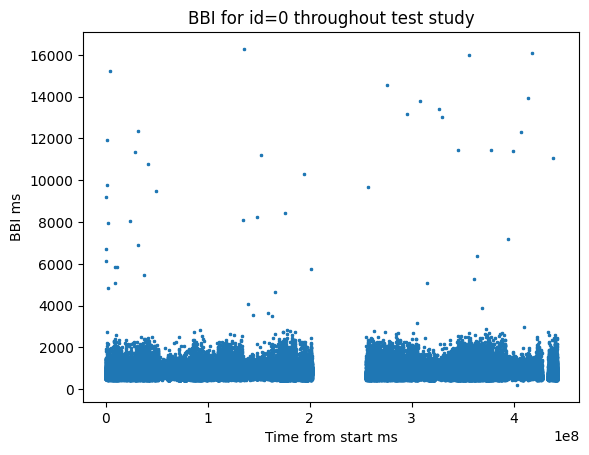

In [ ]:
# lets look at a single user and show their measurements, transforming timestamps as num_hours from the start of data collection
user=0

temp=df.loc[ df['User Id']==user, :]
x=temp['timeLocal_ms']-temp['timeLocal_ms'].min() 
y=temp['BBI (ms)']

fig,ax=plt.subplots()
ax.scatter(x=x, y=y, marker='x', s=3)
ax.set_title(f'BBI for id={user} throughout test study')
ax.set_xlabel('Time from start [ms]')
ax.set_ylabel('BBI ms') # clearly ms is a shitty resolution + there are a few outliers that make BBI values squished

(450.0, 1250.0)

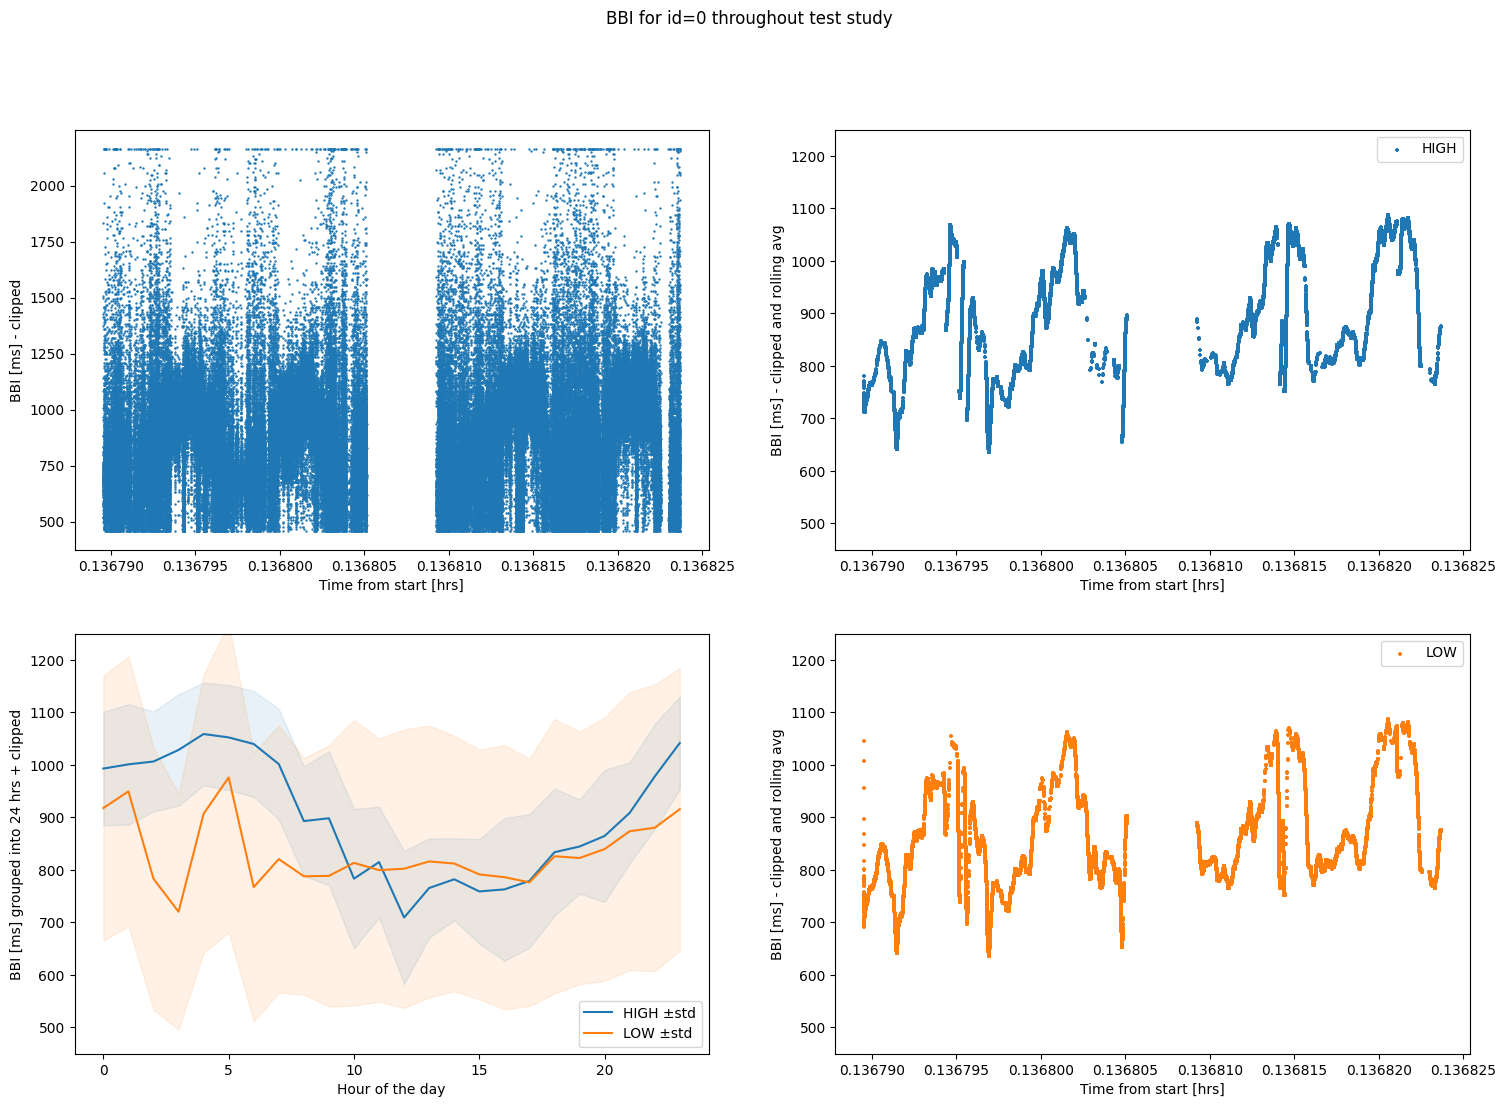

In [295]:
# lets turn ms into mins
# and clip outliers at 99.9%
fig,ax=plt.subplots(nrows=2, ncols=2, figsize=(18,12))
fig.suptitle(f'BBI for id={user} throughout test study')
clrs={'HIGH_CONFIDENCE':'tab:blue', 'LOW_CONFIDENCE':'tab:orange'}

q_h=temp['BBI (ms)'].quantile(0.999)
q_l=temp['BBI (ms)'].quantile(0.001)
w=3_000

# clipped
ax[0,0].scatter(x=pd.to_timedelta(x, unit='ms').dt.total_seconds() /3600, 
                y=temp['BBI (ms)'].clip(upper=q_h, lower=q_l),
                s=.5)
ax[0,0].set_xlabel('Time from start [hrs]')
ax[0,0].set_ylabel('BBI [ms] - clipped')


# clipped + moving average
x=pd.to_timedelta(x, unit='ms').dt.total_seconds() /3600
y=temp['BBI (ms)'].clip(upper=q_h, lower=q_l)\
    .rolling(window=w, min_periods=1).mean()
for status,c in clrs.items():
    selection=temp['Status'] == status # mask
    if status=='HIGH_CONFIDENCE': a=ax[0,1] 
    else: a=ax[1,1]
    a.scatter(x=x[selection], y=y[selection], label=status.split('_')[0], marker='+', s=5, c=c)
    a.legend()
    a.set_xlabel('Time from start [hrs]')
    a.set_ylabel('BBI [ms] - clipped and rolling avg') 
    a.set_ylim((450,1250))


# clipped + groupby hour
hr=pd.to_datetime(temp['timeLocal_ms'], unit='ms').dt.hour
y=temp.groupby([hr, 'Status'])['BBI (ms)']\
    .agg(lambda s: np.mean(s.clip(upper=q_h, lower=q_l)))\
        .unstack('Status')
y_int=temp.groupby([hr, 'Status'])['BBI (ms)']\
    .agg( lambda s: np.std(s.clip(upper=q_h, lower=q_l)) )\
        .unstack('Status')

for status in y.columns:
    ax[1,0].plot(y.index, y[status], label=status.split('_')[0]+' ±std')
    ax[1,0].fill_between(y.index, y[status]-y_int[status], y[status]+y_int[status], color=clrs[status], alpha=0.1)

ax[1,0].legend()    
ax[1,0].set_ylabel('BBI [ms] grouped into 24 hrs + clipped') 
ax[1,0].set_xlabel('Hour of the day')
ax[1,0].set_ylim((450,1250))


In [303]:
df.loc[df['Status']=='HIGH_CONFIDENCE', 'BBI (ms)'].mean()

np.float64(942.9094108446299)

Text(0.5, 1.0, 'Winsorised BBI, grouped by hour of the day')

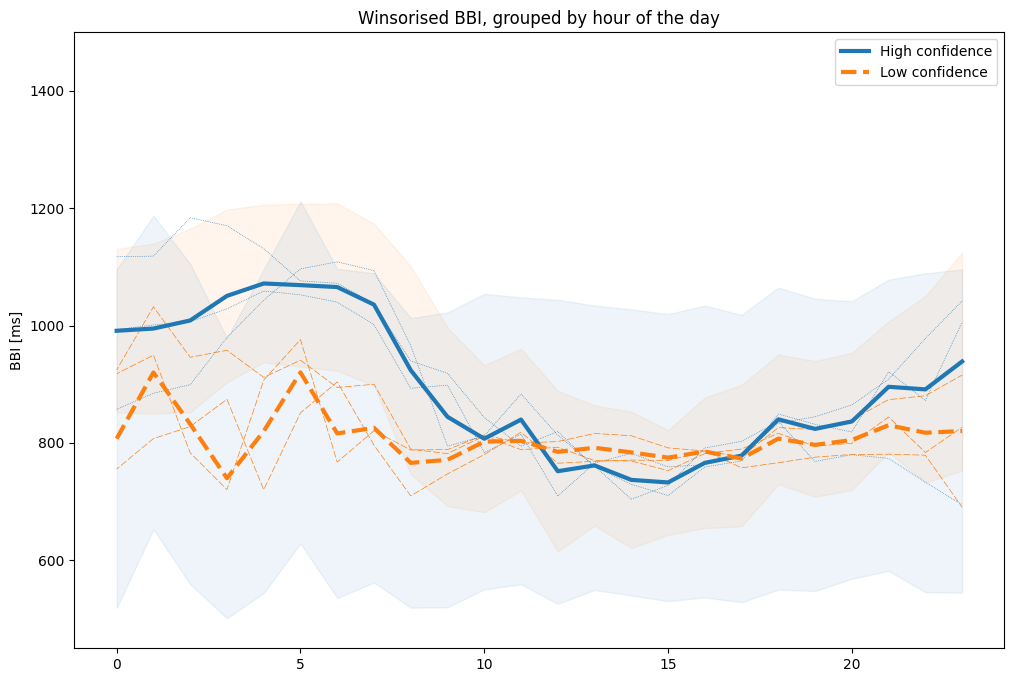

In [327]:
df['User Id'].drop_duplicates()

fig,ax=plt.subplots(nrows=1, ncols=1, figsize=(12,8), sharey=True)

for user in df['User Id'].drop_duplicates():
    temp=df.loc[df['User Id']==user, :]
    q_h=temp['BBI (ms)'].quantile(0.999)
    q_l=temp['BBI (ms)'].quantile(0.001)
    hr=pd.to_datetime(temp['timeLocal_ms'], unit='ms').dt.hour

    y=temp.groupby([hr, 'Status'])['BBI (ms)']\
        .agg(lambda s: np.mean(s.clip(upper=q_h, lower=q_l)))\
            .unstack('Status')
    y_int=temp.groupby([hr, 'Status'])['BBI (ms)']\
        .agg( lambda s: np.std(s.clip(upper=q_h, lower=q_l)) )\
            .unstack('Status')

    for status in y.columns:
        if status=='HIGH_CONFIDENCE': 
            linestyle='dotted'
            c='tab:blue'
        else: 
            linestyle=(5, (10, 3))
            c='tab:orange'
        ax.plot(y.index, y[status], linewidth=0.5, linestyle=linestyle, c=c) #label=status.split('_')[0]+' ±std',
        #ax.fill_between(y.index, y[status]-y_int[status], y[status]+y_int[status], color=clrs[status], alpha=0.1)

hr=pd.to_datetime(df['timeLocal_ms'], unit='ms').dt.hour
y=df.groupby([hr, 'Status'])['BBI (ms)']\
        .agg(lambda s: np.mean(s.clip(upper=q_h, lower=q_l)))\
            .unstack('Status')
y_int=df.groupby([hr, 'Status'])['BBI (ms)']\
        .agg( lambda s: np.std(s.clip(upper=q_h, lower=q_l)) )\
            .unstack('Status')

ax.plot(y.index, y['HIGH_CONFIDENCE'], linewidth=3, linestyle='solid', c='tab:blue', label='High confidence')
ax.plot(y.index, y['LOW_CONFIDENCE'], linewidth=3, linestyle='dashed', c='tab:orange', label='Low confidence')
ax.fill_between(y.index, y['HIGH_CONFIDENCE']-y_int['HIGH_CONFIDENCE'], y['HIGH_CONFIDENCE']+y_int['HIGH_CONFIDENCE'], color='tab:orange', alpha=0.075)
ax.fill_between(y.index, y['LOW_CONFIDENCE']-y_int['LOW_CONFIDENCE'], y['LOW_CONFIDENCE']+y_int['LOW_CONFIDENCE'], color='tab:blue', alpha=0.075)
ax.legend()    
ax.set_ylabel('BBI [ms]') 
ax.set_ylim((450,1500))
ax.set_title(f'Winsorised BBI, grouped by hour of the day')
    


In [21]:
# let's see how much BBI values vary between users (level0), confidence levels (level1) and hours of the day (level2)
hour = pd.to_datetime(df['timeLocal_ms'], unit='ms').dt.hour # level2 groupby column

gr = df.groupby(['User Id', 'Status', hour])['BBI (ms)']\
    .agg(['min', 'max', 'median', 'std', 'size'])

gr.groupby(level=[0,1]).mean().astype(int)\
    .rename(columns={'size':'num BBI measurements per hour', 'min':'min BBI', 'max':'max BBI', 'median':'median BBI', 'std':'std BBI'})

min BBI  max BBI  median BBI  std BBI  \
User Id Status                                                   
1       HIGH_CONFIDENCE      503     1734         897      107   
        LOW_CONFIDENCE       442    10379         797      332   
2       HIGH_CONFIDENCE      517     1695         932      119   
        LOW_CONFIDENCE       464     2347         792      259   
3       HIGH_CONFIDENCE      483     1720         855      140   
        LOW_CONFIDENCE       457     2765         724      255   

                         num BBI measurements per hour  
User Id Status                                          
1       HIGH_CONFIDENCE                           6757  
        LOW_CONFIDENCE                            7027  
2       HIGH_CONFIDENCE                           4033  
        LOW_CONFIDENCE                            3734  
3       HIGH_CONFIDENCE                           3913  
        LOW_CONFIDENCE                            5430

Text(0.5, 0, 'Hour')

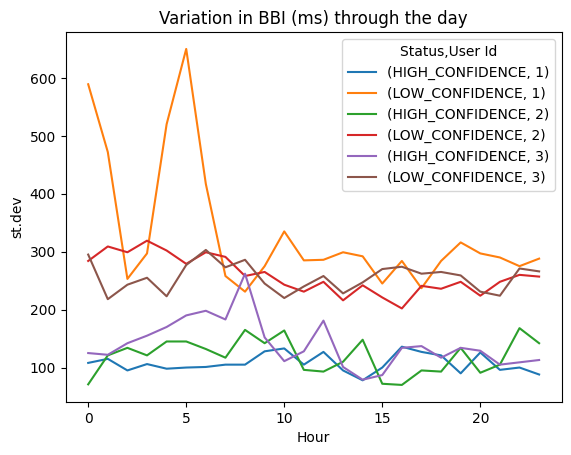

In [22]:
# plot hourly std stratified by user and confidence
ax = gr['std'].unstack(['Status', 'User Id']).round(0).plot()

ax.set_title('Variation in BBI (ms) through the day')
ax.set_ylabel('st.dev')
ax.set_xlabel('Hour')

In [23]:
# lets see how moments etc look like in groups, and also across entire data, and for reference normal dist of given mean/std

f = lambda v: [ np.mean(v).round(1), np.median(v).round(1), np.std(v).round(1), scipy.stats.skew(v).round(1), scipy.stats.kurtosis(v).round(1)]

# in stratified data
gr_robust = df.groupby(['User Id', 'Status', hour])['BBI (ms)']\
    .agg(['mean', 'median', 'std', 'skew', pd.Series.kurt ])\
    .groupby(level=[0,1]).mean().round(1)\
    .rename(columns={'mean':'mean BBI', 'median':'median BBI'})

# all data
gr_robust.loc[ ('all', 'all'), : ] = f( df['BBI (ms)'] )

# ref dist
ref_norm = scipy.stats.norm(loc=df['BBI (ms)'].mean(), scale=df['BBI (ms)'].std()) # loc is mean, scale is std
x = np.linspace(ref_norm.ppf(0.01), ref_norm.ppf(0.99), 1000)
gr_robust.loc[ ('ref', 'ref'), : ] = f( x )

gr_robust
#gr_robust.groupby(level=[0,1]).mean().round(1)\
#    .rename(columns={'mean':'mean BBI', 'median':'median BBI'}) # seems like in the low confidence group 

mean BBI  median BBI    std  skew   kurt
User Id Status                                                   
1       HIGH_CONFIDENCE     900.1       897.9  107.6   0.4    5.0
        LOW_CONFIDENCE      837.3       797.1  332.3   9.2  265.7
2       HIGH_CONFIDENCE     927.1       932.4  119.8   0.2    4.6
        LOW_CONFIDENCE      842.0       792.5  259.3   1.4    3.7
3       HIGH_CONFIDENCE     858.6       855.5  140.2   0.8    4.6
        LOW_CONFIDENCE      783.1       724.8  255.6   2.0    9.3
all     all                 866.9       841.0  245.8   5.0  206.3
ref     ref                 866.9       866.9  330.4   0.0   -1.2

In [24]:
userid_map

{'69aa9a01c272d7436ea5db59': 1,
 '69ab0d5ea24478775034fc27': 2,
 '69ab0d65a24478775034fc29': 3}

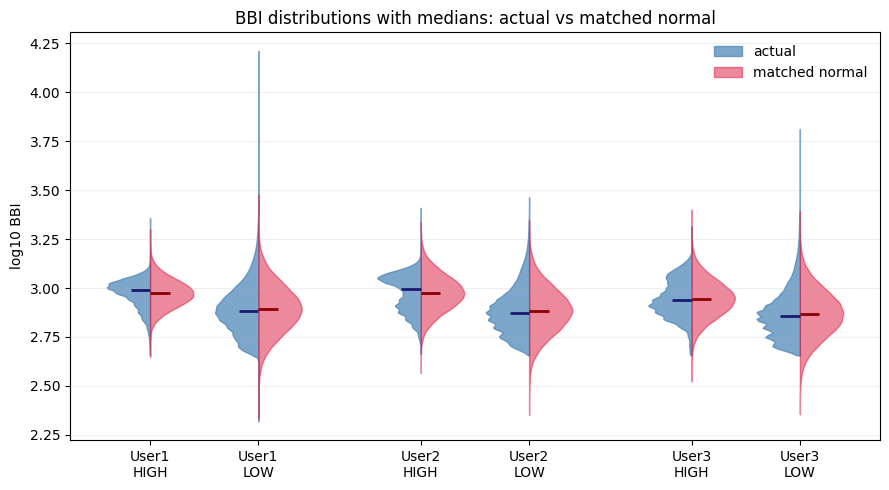

In [31]:
# half-violin comparison:
# left half  = actual BBI distribution
# right half = matched normal with sample mean/std

#q99 = df['BBI (ms)'].quantile(0.995)
plot_df = df.copy()
plot_df['BBI (ms)'] = np.log10(df['BBI (ms)']) #(df.groupby(['User Id', 'Status'])['BBI (ms)']\
                      # .transform(lambda s: np.log10(s.clip(upper=s.quantile(0.999)))))


fig, ax = plt.subplots(figsize=(9, 5))

labels = []
positions = []
pos = 1

for user in sorted(plot_df['User Id'].dropna().unique()):
    for status in sorted(plot_df['Status'].dropna().unique()):
        s = plot_df.loc[
            (plot_df['User Id'] == user) & (plot_df['Status'] == status),
            'BBI (ms)'
        ].dropna().to_numpy()

        if len(s) < 5:
            continue

        mu = s.mean()
        sigma = s.std(ddof=1)
        if sigma == 0 or np.isnan(sigma):
            continue

        normal_ref = np.random.normal(loc=mu, scale=sigma, size=len(s))

        v_actual = ax.violinplot(
            [s],
            positions=[pos],
            widths=0.8,
            showmeans=False,
            showmedians=False,
            showextrema=False
        )

        v_normal = ax.violinplot(
            [normal_ref],
            positions=[pos],
            widths=0.8,
            showmeans=False,
            showmedians=False,
            showextrema=False
        )

        # keep only left half for actual data
        body_actual = v_actual['bodies'][0]
        verts = body_actual.get_paths()[0].vertices
        verts[:, 0] = np.minimum(verts[:, 0], pos)
        body_actual.set_facecolor('steelblue')
        body_actual.set_edgecolor('steelblue')
        body_actual.set_alpha(0.7)

        # keep only right half for matched normal
        body_normal = v_normal['bodies'][0]
        verts = body_normal.get_paths()[0].vertices
        verts[:, 0] = np.maximum(verts[:, 0], pos)
        body_normal.set_facecolor('crimson')
        body_normal.set_edgecolor('crimson')
        body_normal.set_alpha(0.5)

        # median lines
        med_actual = np.median(s)
        med_normal = np.median(normal_ref)
        ax.hlines(med_actual, pos - 0.18, pos, color='midnightblue', lw=2)
        ax.hlines(med_normal, pos, pos + 0.18, color='darkred', lw=2)

        labels.append(f'User{user}\n{status.replace("_CONFIDENCE", "").replace("_", " ")}')
        positions.append(pos)
        pos += 1

    pos += 0.5

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel('log10 BBI')
ax.set_title('BBI distributions with medians: actual vs matched normal')
ax.grid(axis='y', alpha=0.2)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor='steelblue', edgecolor='steelblue', alpha=0.7, label='actual'),
    Patch(facecolor='crimson', edgecolor='crimson', alpha=0.5, label='matched normal'),
]
ax.legend(handles=legend_handles, frameon=False)

plt.tight_layout()
plt.show()


In [50]:
grouped = df.loc[ (df['User Id']==2)& (df['Status']=='HIGH_CONFIDENCE'), ['BBI (ms)', 'timeLocal_ms']]\
    .reset_index(drop=True)

In [40]:
grouped['hour'] = pd.to_datetime(grouped['timeLocal_ms'], unit='ms').dt.hour

In [51]:
grouped['BBI (ms)'] = grouped['BBI (ms)'].rolling(window=100, min_periods=1).median()

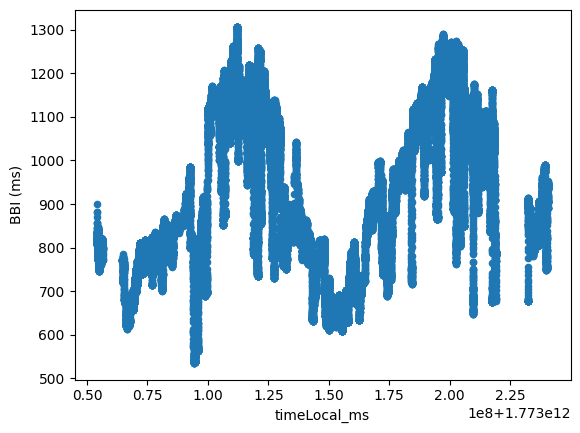

In [52]:
grouped.plot(kind='scatter', x='timeLocal_ms', y='BBI (ms)')
plt.show()

<Axes: xlabel='hour'>

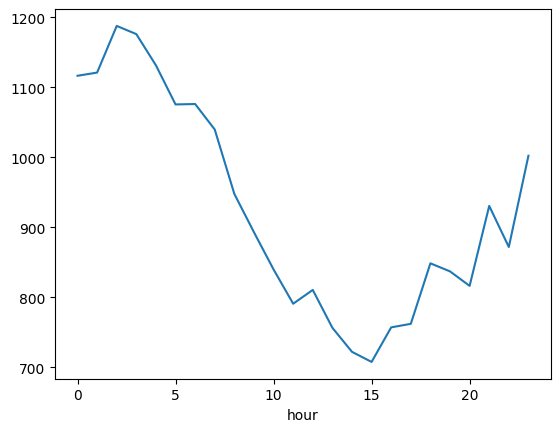

In [44]:
grouped.groupby('hour')['BBI (ms)'].mean().plot()

In [28]:
  \
        .rolling(window=100, min_periods=1)\
            .median()\
                .plot()

hour = pd.to_datetime(df['timeLocal_ms'], unit='ms').dt.hour # level2 groupby column

IndentationError: unexpected indent (26466485.py, line 2)